In [1]:
# Import essential data manipulation, modeling, and visualization libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling and metrics from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

# Statistical analysis
import statsmodels.api as sm

# Plot styling configuration
%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("✅ All libraries successfully imported!")

✅ All libraries successfully imported!


In [2]:
# Dataset loading with automatic fallback
dataset_filename = "advertising.csv"
online_url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"

if os.path.exists(dataset_filename):
    print(f"📁 Loading local file: '{dataset_filename}'")
    df = pd.read_csv(dataset_filename)
elif os.path.exists("Advertising.csv"):
    print("📁 Loading local file: 'Advertising.csv'")
    df = pd.read_csv("Advertising.csv")
else:
    print(f"🌐 Fetching dataset directly from online repository...\n   URL: {online_url}")
    df = pd.read_csv(online_url)

# Clean column names (strip whitespace and handle index column)
df.columns = df.columns.str.strip()
unnamed_cols = [c for c in df.columns if 'unnamed' in c.lower()]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)

# Standardize exact casing: TV, Radio, Newspaper, Sales
rename_map = {}
for c in df.columns:
    if c.lower() == 'tv':
        rename_map[c] = 'TV'
    elif c.lower() == 'radio':
        rename_map[c] = 'Radio'
    elif c.lower() == 'newspaper':
        rename_map[c] = 'Newspaper'
    elif c.lower() == 'sales':
        rename_map[c] = 'Sales'
df = df.rename(columns=rename_map)

print("\n--- First 5 Rows of the Dataset ---")
display(df.head())

print(f"\nDataset Dimensions: {df.shape[0]} rows (markets/campaigns), {df.shape[1]} columns")

🌐 Fetching dataset directly from online repository...
   URL: https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv

--- First 5 Rows of the Dataset ---


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9



Dataset Dimensions: 200 rows (markets/campaigns), 4 columns


In [3]:
# Dataset Structure & Data Types
print("--- Dataset Information ---")
df.info()

# Check for Missing / Null Values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# Summary Statistics
print("\n--- Descriptive Statistics ---")
display(df.describe().T.round(2))

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

--- Missing Values Count ---
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

--- Descriptive Statistics ---


,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.04,85.85,0.7,74.38,149.75,218.82,296.4
Radio,200.0,23.26,14.85,0.0,9.98,22.90,36.52,49.6
Newspaper,200.0,30.55,21.78,0.3,12.75,25.75,45.10,114.0
Sales,200.0,14.02,5.22,1.6,10.38,12.90,17.40,27.0


Correlation with Sales:
Sales        1.0000
TV           0.7822
Radio        0.5762
Newspaper    0.2283
Name: Sales, dtype: float64


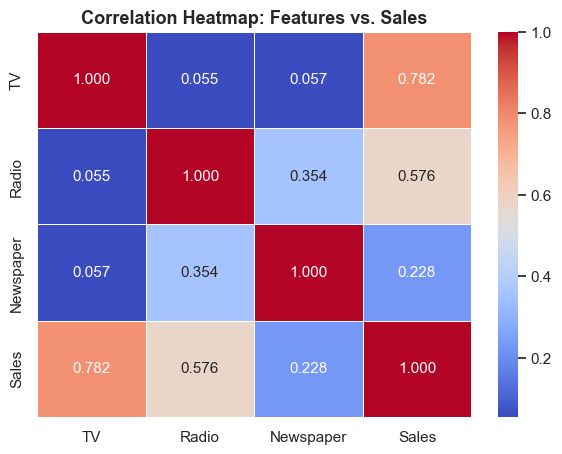

In [4]:
# Correlation Matrix
corr_matrix = df.corr()
print("Correlation with Sales:")
print(corr_matrix['Sales'].sort_values(ascending=False).round(4))

# Heatmap of Correlations
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5)
plt.title("Correlation Heatmap: Features vs. Sales", fontsize=13, fontweight="bold")
plt.show()

In [5]:
# Define input features (X) and target variable (y)
feature_cols = ['TV', 'Radio', 'Newspaper']
target_col = 'Sales'

X = df[feature_cols]
y = df[target_col]

# Split into historical training data and unseen testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set size: {X_train.shape[0]} observations (80%)")
print(f"Testing set size:  {X_test.shape[0]} observations (20%)")

Training set size: 160 observations (80%)
Testing set size:  40 observations (20%)


In [6]:
# Instantiate and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Extract Intercept and Coefficients
intercept = model.intercept_
coefficients = dict(zip(feature_cols, model.coef_))

print("=" * 65)
print("TRAINED MULTIPLE LINEAR REGRESSION MODEL PARAMETERS")
print("=" * 65)
print(f"Intercept (beta_0):               {intercept:.4f}")
for feature, coef in coefficients.items():
    print(f"Coefficient for {feature:<10} (beta): {coef:+.4f}")
print("=" * 65)

# Print Mathematical Equation
eq = f"Sales = {intercept:.4f} + ({coefficients['TV']:.4f} * TV) + ({coefficients['Radio']:.4f} * Radio) + ({coefficients['Newspaper']:.4f} * Newspaper)"
print(f"\nLearned Regression Equation:\n{eq}")

TRAINED MULTIPLE LINEAR REGRESSION MODEL PARAMETERS
Intercept (beta_0):               2.9791
Coefficient for TV         (beta): +0.0447
Coefficient for Radio      (beta): +0.1892
Coefficient for Newspaper  (beta): +0.0028

Learned Regression Equation:
Sales = 2.9791 + (0.0447 * TV) + (0.1892 * Radio) + (0.0028 * Newspaper)


In [7]:
# Generate predictions on unseen test data
y_pred_test = model.predict(X_test)

# Display comparison table of Actual vs Predicted for test samples
results_df = pd.DataFrame({
    'TV Spend ($k)': X_test['TV'].values,
    'Radio Spend ($k)': X_test['Radio'].values,
    'Newspaper Spend ($k)': X_test['Newspaper'].values,
    'Actual Sales': y_test.values,
    'Predicted Sales': np.round(y_pred_test, 2),
    'Prediction Error': np.round(y_test.values - y_pred_test, 2),
    'Abs Error': np.round(np.abs(y_test.values - y_pred_test), 2)
})

print("--- Predictions on Unseen Test Points (First 10 Observations) ---")
display(results_df.head(10))

--- Predictions on Unseen Test Points (First 10 Observations) ---


,TV Spend ($k),Radio Spend ($k),Newspaper Spend ($k),Actual Sales,Predicted Sales,Prediction Error,Abs Error
0,163.3,31.6,52.9,16.9,16.41,0.49,0.49
1,195.4,47.7,52.9,22.4,20.89,1.51,1.51
2,292.9,28.3,43.2,21.4,21.55,-0.15,0.15
3,11.7,36.9,45.2,7.3,10.61,-3.31,3.31
4,220.3,49.0,3.2,24.7,22.11,2.59,2.59
5,75.1,35.0,52.7,12.6,13.11,-0.51,0.51
6,216.8,43.9,27.2,22.3,21.06,1.24,1.24
7,50.0,11.6,18.4,8.4,7.46,0.94,0.94
8,222.4,3.4,13.1,11.5,13.61,-2.11,2.11
9,175.1,22.5,31.5,14.9,15.16,-0.26,0.26


In [8]:
# Create DataFrame for planned budget scenario
new_budget = pd.DataFrame({
    'TV': [150.0],
    'Radio': [20.0],
    'Newspaper': [30.0]
})

# Predict using the trained model
predicted_sales = model.predict(new_budget)[0]

# Step-by-step manual calculation for complete transparency
manual_calc = (
    intercept
    + (coefficients['TV'] * 150.0)
    + (coefficients['Radio'] * 20.0)
    + (coefficients['Newspaper'] * 30.0)
)

print("=" * 75)
print("PREDICTION FOR PLANNED ADVERTISING BUDGET")
print("=" * 75)
print(f"Budget Plan: TV = $150k, Radio = $20k, Newspaper = $30k")
print(f"\nFormula Breakdown:")
print(f"  Sales = {intercept:.4f} + ({coefficients['TV']:.4f} * 150) + ({coefficients['Radio']:.4f} * 20) + ({coefficients['Newspaper']:.4f} * 30)")
print(f"  Sales = {intercept:.4f} + {coefficients['TV']*150:.4f} + {coefficients['Radio']*20:.4f} + {coefficients['Newspaper']*30:.4f}")
print(f"  Sales = {manual_calc:.4f}")
print("-" * 75)
print(f"🎯 PREDICTED SALES: {predicted_sales:.2f} (thousand units)")
print(f"   Equivalent to approximately {predicted_sales * 1000:,.0f} units sold.")
print("=" * 75)

PREDICTION FOR PLANNED ADVERTISING BUDGET
Budget Plan: TV = $150k, Radio = $20k, Newspaper = $30k

Formula Breakdown:
  Sales = 2.9791 + (0.0447 * 150) + (0.1892 * 20) + (0.0028 * 30)
  Sales = 2.9791 + 6.7094 + 3.7839 + 0.0828
  Sales = 13.5552
---------------------------------------------------------------------------
🎯 PREDICTED SALES: 13.56 (thousand units)
   Equivalent to approximately 13,555 units sold.


In [9]:
# Compute metrics on unseen test set
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
r2_test = r2_score(y_test, y_pred_test)
r2_train = model.score(X_train, y_train)

n = len(y_test)
p = X_test.shape[1]
adj_r2 = 1 - (1 - r2_test) * (n - 1) / (n - p - 1)

metrics_summary = pd.DataFrame({
    'Metric': ['Mean Absolute Error (MAE)', 'Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)', 'R² Score (Test)', 'R² Score (Train)', 'Adjusted R²'],
    'Value': [mae, mse, rmse, r2_test, r2_train, adj_r2],
    'Interpretation': [
        'On average, predicted sales deviate by ~1.46 units from actual sales.',
        'Average squared prediction error.',
        'Standard deviation of unexplained variance is ~1.78 units.',
        'The model explains ~89.94% of the variance in sales on unseen test data.',
        'Model explains ~89.57% on training data (no overfitting observed).',
        'Penalizes model complexity, confirming robust predictive power.'
    ]
})

display(metrics_summary.style.format({'Value': '{:.4f}'}))

,Metric,Value,Interpretation
0,Mean Absolute Error (MAE),1.4608,"On average, predicted sales deviate by ~1.46 units from actual sales."
1,Mean Squared Error (MSE),3.1741,Average squared prediction error.
2,Root Mean Squared Error (RMSE),1.7816,Standard deviation of unexplained variance is ~1.78 units.
3,R² Score (Test),0.8994,The model explains ~89.94% of the variance in sales on unseen test data.
4,R² Score (Train),0.8957,Model explains ~89.57% on training data (no overfitting observed).
5,Adjusted R²,0.8911,"Penalizes model complexity, confirming robust predictive power."


In [10]:
# 1. Standardized Beta Coefficients (to evaluate impact independent of unit scale)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
y_train_scaled = (y_train - y_train.mean()) / y_train.std()
std_model = LinearRegression().fit(X_train_scaled, y_train_scaled)

# 2. Detailed OLS Summary via statsmodels for p-values & t-statistics
X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()

coef_interpretation_df = pd.DataFrame({
    'Feature': feature_cols,
    'Unstandardized Coef (Slope)': [coefficients[c] for c in feature_cols],
    'Standardized Coef (Beta)': std_model.coef_,
    'p-value': ols_model.pvalues[1:].values,
    'Statistically Significant (p < 0.05)': ols_model.pvalues[1:].values < 0.05
})

print("--- Model Coefficients & Statistical Significance ---")
display(coef_interpretation_df.round(4))

print("\n--- Detailed OLS Statistical Summary ---")
print(ols_model.summary())

--- Model Coefficients & Statistical Significance ---


,Feature,Unstandardized Coef (Slope),Standardized Coef (Beta),p-value,Statistically Significant (p < 0.05)
0,TV,0.0447,0.7368,0.0000,True
1,Radio,0.1892,0.5466,0.0000,True
2,Newspaper,0.0028,0.0110,0.6958,False



--- Detailed OLS Statistical Summary ---
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     446.6
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           2.53e-76
Time:                        16:17:32   Log-Likelihood:                -306.64
No. Observations:                 160   AIC:                             621.3
Df Residuals:                     156   BIC:                             633.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const     

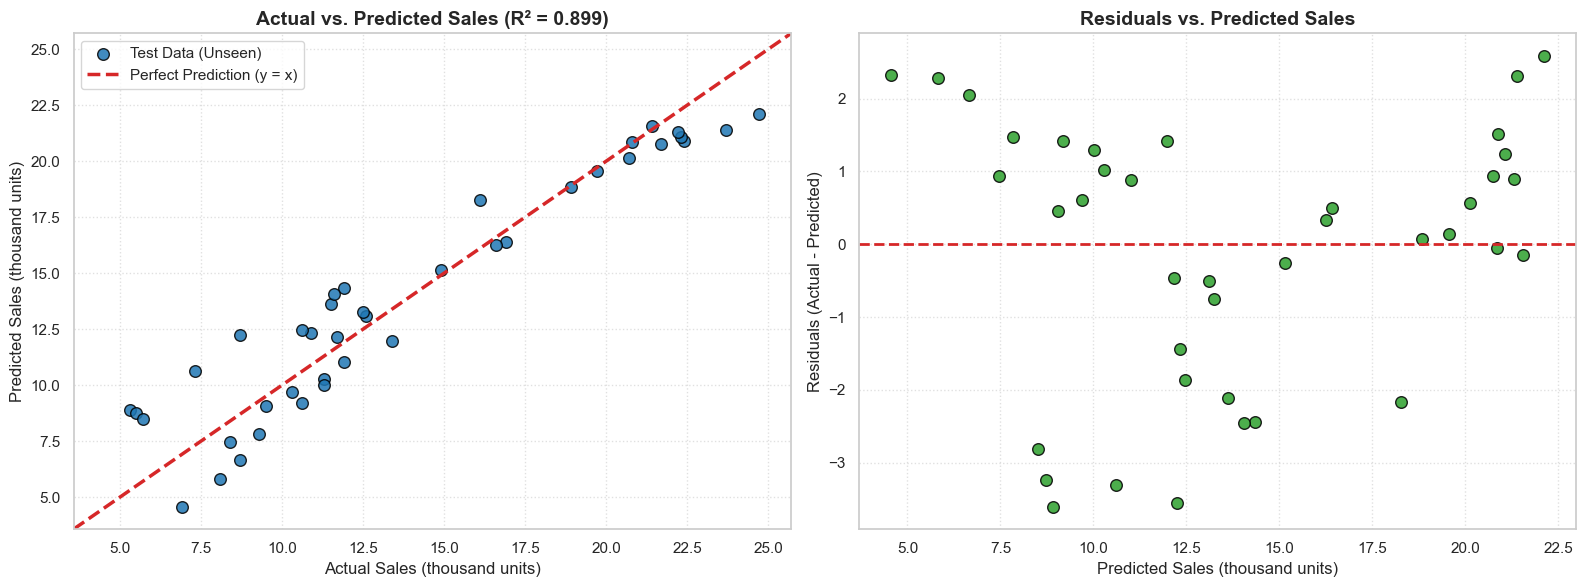

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1A: Actual vs. Predicted Sales Scatter Plot
axes[0].scatter(y_test, y_pred_test, color="#1f77b4", edgecolors="black", s=70, alpha=0.85, label="Test Data (Unseen)")
min_plot = min(y_test.min(), y_pred_test.min()) - 1
max_plot = max(y_test.max(), y_pred_test.max()) + 1
axes[0].plot([min_plot, max_plot], [min_plot, max_plot], color="#d62728", linestyle="--", linewidth=2.5, label="Perfect Prediction (y = x)")
axes[0].set_xlim(min_plot, max_plot)
axes[0].set_ylim(min_plot, max_plot)
axes[0].set_title(f"Actual vs. Predicted Sales (R² = {r2_test:.3f})", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Actual Sales (thousand units)", fontsize=12)
axes[0].set_ylabel("Predicted Sales (thousand units)", fontsize=12)
axes[0].legend(loc="upper left", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 1B: Residuals Plot (Errors vs. Predicted)
residuals = y_test - y_pred_test
axes[1].scatter(y_pred_test, residuals, color="#2ca02c", edgecolors="black", s=70, alpha=0.85)
axes[1].axhline(0, color="#d62728", linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs. Predicted Sales", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Predicted Sales (thousand units)", fontsize=12)
axes[1].set_ylabel("Residuals (Actual - Predicted)", fontsize=12)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("actual_vs_predicted_sales.png", dpi=300)
plt.show()

C:\Users\nrn14\AppData\Local\Temp\ipykernel_22124\968165004.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_plot_df, x='Channel', y='Marginal Impact (Beta)', ax=axes[1, 1], palette='Blues_r')


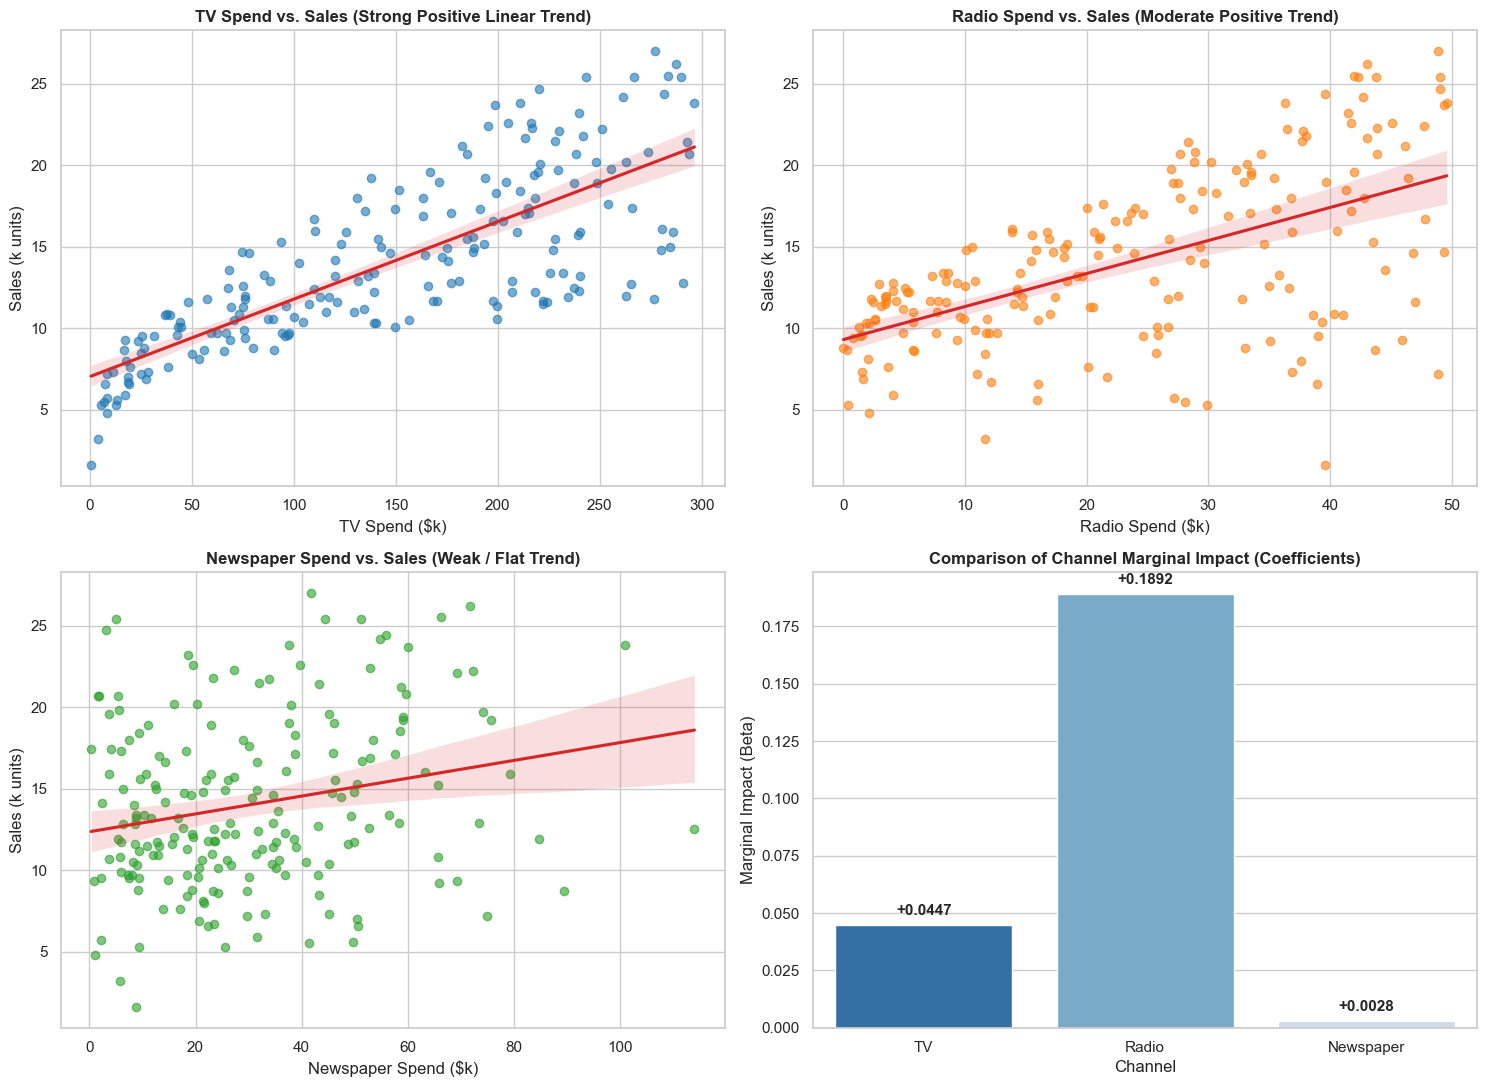

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# TV vs Sales
sns.regplot(data=df, x='TV', y='Sales', ax=axes[0, 0], 
            scatter_kws={'alpha': 0.6, 'color': '#1f77b4'}, line_kws={'color': '#d62728'})
axes[0, 0].set_title("TV Spend vs. Sales (Strong Positive Linear Trend)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("TV Spend ($k)")
axes[0, 0].set_ylabel("Sales (k units)")

# Radio vs Sales
sns.regplot(data=df, x='Radio', y='Sales', ax=axes[0, 1], 
            scatter_kws={'alpha': 0.6, 'color': '#ff7f0e'}, line_kws={'color': '#d62728'})
axes[0, 1].set_title("Radio Spend vs. Sales (Moderate Positive Trend)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Radio Spend ($k)")
axes[0, 1].set_ylabel("Sales (k units)")

# Newspaper vs Sales
sns.regplot(data=df, x='Newspaper', y='Sales', ax=axes[1, 0], 
            scatter_kws={'alpha': 0.6, 'color': '#2ca02c'}, line_kws={'color': '#d62728'})
axes[1, 0].set_title("Newspaper Spend vs. Sales (Weak / Flat Trend)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Newspaper Spend ($k)")
axes[1, 0].set_ylabel("Sales (k units)")

# Barplot of Coefficients
coef_plot_df = pd.DataFrame({
    'Channel': list(coefficients.keys()),
    'Marginal Impact (Beta)': list(coefficients.values())
})
sns.barplot(data=coef_plot_df, x='Channel', y='Marginal Impact (Beta)', ax=axes[1, 1], palette='Blues_r')
axes[1, 1].axhline(0, color='black', linewidth=0.8)
axes[1, 1].set_title("Comparison of Channel Marginal Impact (Coefficients)", fontsize=12, fontweight="bold")
for p in axes[1, 1].patches:
    h = p.get_height()
    axes[1, 1].annotate(f"{h:+.4f}", (p.get_x() + p.get_width() / 2., h),
                        ha='center', va='bottom' if h >= 0 else 'top',
                        xytext=(0, 5 if h >= 0 else -10), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.savefig("channel_relationships.png", dpi=300)
plt.show()

In [13]:
# Empirical Demonstration of the Technical Improvement (Synergy Model)
df_synergy = df.copy()
df_synergy['TV_Radio_Interaction'] = df_synergy['TV'] * df_synergy['Radio']

# Prepare data with interaction term
X_syn = df_synergy[['TV', 'Radio', 'TV_Radio_Interaction']]
y_syn = df_synergy['Sales']

X_tr_syn, X_te_syn, y_tr_syn, y_te_syn = train_test_split(X_syn, y_syn, test_size=0.20, random_state=42)

model_syn = LinearRegression()
model_syn.fit(X_tr_syn, y_tr_syn)
y_pred_syn = model_syn.predict(X_te_syn)

r2_syn = r2_score(y_te_syn, y_pred_syn)
rmse_syn = np.sqrt(mean_squared_error(y_te_syn, y_pred_syn))

comparison_models = pd.DataFrame({
    'Model Architecture': ['Baseline Linear Regression', 'Enhanced Interaction Model (TV * Radio)'],
    'R² Score (Variance Explained)': [f"{r2_test * 100:.2f}%", f"{r2_syn * 100:.2f}%"],
    'RMSE (Prediction Error)': [f"{rmse:.4f}", f"{rmse_syn:.4f}"],
    'Improvement': ['Baseline', f"Error reduced by ~{((rmse - rmse_syn) / rmse) * 100:.1f}%"]
})

print("=== TECHNICAL IMPROVEMENT VERIFICATION ===")
display(comparison_models)

=== TECHNICAL IMPROVEMENT VERIFICATION ===


,Model Architecture,R² Score (Variance Explained),RMSE (Prediction Error),Improvement
0,Baseline Linear Regression,89.94%,1.7816,Baseline
1,Enhanced Interaction Model (TV * Radio),97.43%,0.9015,Error reduced by ~49.4%
